In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

In [11]:
url = "https://raw.githubusercontent.com/Suujeet/Ai-bootcamp/main/healthcare-dataset-stroke-data.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully
Shape of dataset: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [13]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [14]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [15]:
df["stroke"].value_counts()

,count
stroke,
0,4861
1,249


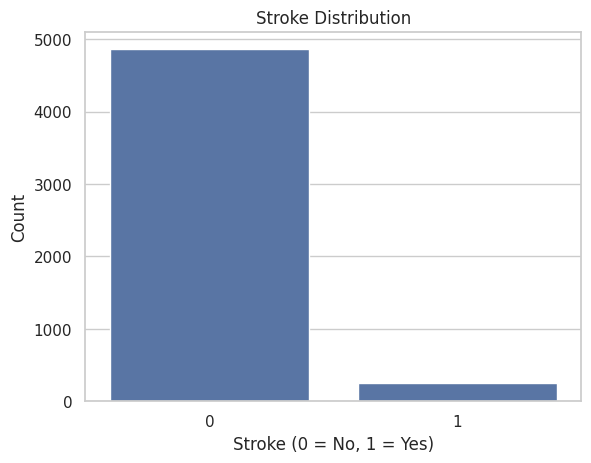

In [16]:
sns.countplot(data=df, x="stroke")
plt.title("Stroke Distribution")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

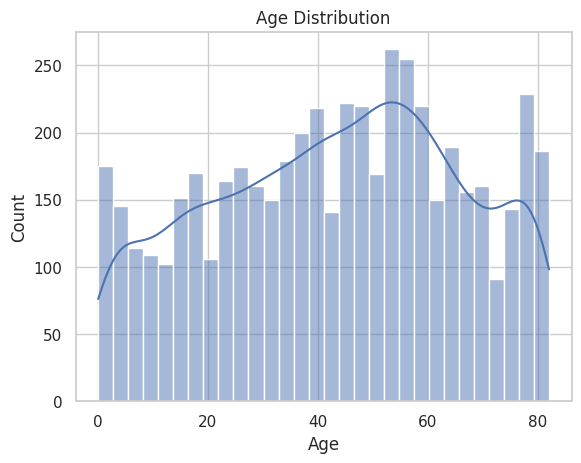

In [17]:
sns.histplot(data=df, x="age", bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()

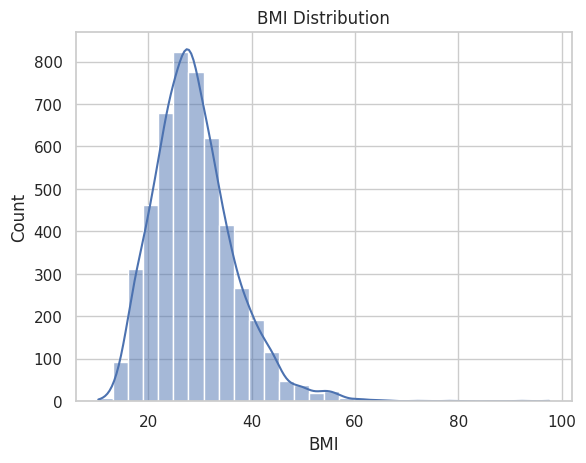

In [18]:
sns.histplot(data=df, x="bmi", bins=30, kde=True)
plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.show()

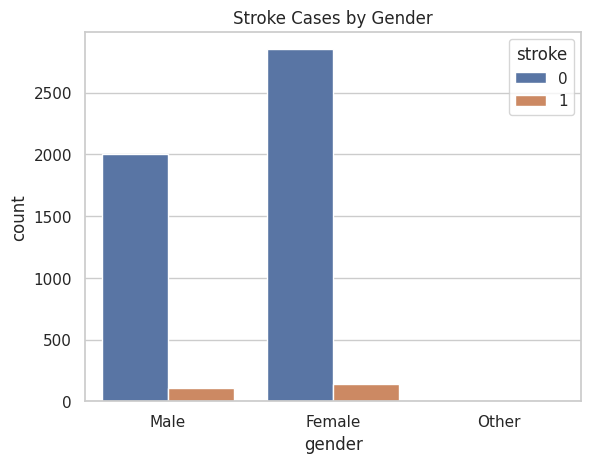

In [19]:
sns.countplot(data=df, x="gender", hue="stroke")
plt.title("Stroke Cases by Gender")
plt.show()

In [20]:
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

print(df.isnull().sum())

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [21]:
df = df.drop_duplicates()

df = df[df["gender"] != "Other"]

print(df.shape)

(5109, 12)


In [22]:
le = LabelEncoder()

df["gender"] = le.fit_transform(df["gender"])
df["ever_married"] = le.fit_transform(df["ever_married"])
df["work_type"] = le.fit_transform(df["work_type"])
df["Residence_type"] = le.fit_transform(df["Residence_type"])
df["smoking_status"] = le.fit_transform(df["smoking_status"])

df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,1,67.0,0,1,1,2,1,228.69,36.6,1,1
1,51676,0,61.0,0,0,1,3,0,202.21,28.1,2,1
2,31112,1,80.0,0,1,1,2,0,105.92,32.5,2,1
3,60182,0,49.0,0,0,1,2,1,171.23,34.4,3,1
4,1665,0,79.0,1,0,1,3,0,174.12,24.0,2,1


In [23]:
X = df.drop(["id", "stroke"], axis=1)
y = df["stroke"]

print(X.head())
print(y.head())

   gender   age  hypertension  heart_disease  ever_married  work_type  \
0       1  67.0             0              1             1          2   
1       0  61.0             0              0             1          3   
2       1  80.0             0              1             1          2   
3       0  49.0             0              0             1          2   
4       0  79.0             1              0             1          3   

   Residence_type  avg_glucose_level   bmi  smoking_status  
0               1             228.69  36.6               1  
1               0             202.21  28.1               2  
2               0             105.92  32.5               2  
3               1             171.23  34.4               3  
4               0             174.12  24.0               2  
0    1
1    1
2    1
3    1
4    1
Name: stroke, dtype: int64


In [24]:
scaler = StandardScaler()

X = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

X.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,1.189791,1.051242,-0.328637,4.184599,0.723678,-0.153852,0.983884,2.706450,1.004893,-0.351819
1,-0.840484,0.785889,-0.328637,-0.238972,0.723678,0.763335,-1.016380,2.121652,-0.099142,0.581434
2,1.189791,1.626174,-0.328637,4.184599,0.723678,-0.153852,-1.016380,-0.004867,0.472358,0.581434
3,-0.840484,0.255182,-0.328637,-0.238972,0.723678,-0.153852,0.983884,1.437473,0.719142,1.514687
4,-0.840484,1.581949,3.042866,-0.238972,0.723678,0.763335,-1.016380,1.501297,-0.631677,0.581434


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4087, 10)
Testing data: (1022, 10)


In [26]:
lr = LogisticRegression(class_weight="balanced", max_iter=1000)

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:, 1]

In [27]:
print("Logistic Regression Results")

print("Accuracy:", accuracy_score(y_test, lr_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

print("\nROC-AUC Score:")
print(roc_auc_score(y_test, lr_prob))

Logistic Regression Results
Accuracy: 0.735812133072407

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.73      0.84       972
           1       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.53      1022
weighted avg       0.94      0.74      0.81      1022


Confusion Matrix:
[[712 260]
 [ 10  40]]

ROC-AUC Score:
0.8363168724279835


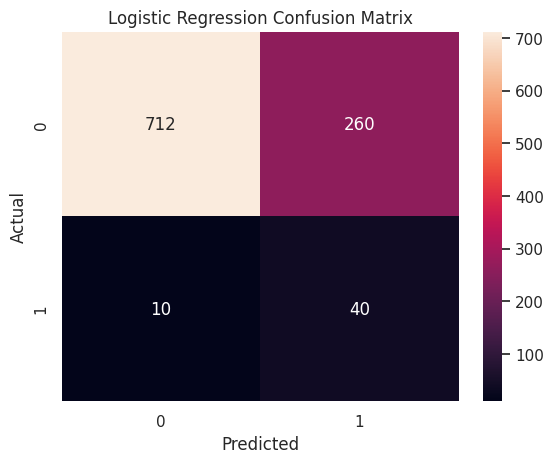

In [28]:
sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt="d")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [29]:
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

In [30]:
print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nROC-AUC Score:")
print(roc_auc_score(y_test, rf_prob))

Random Forest Results
Accuracy: 0.9500978473581213

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022


Confusion Matrix:
[[971   1]
 [ 50   0]]

ROC-AUC Score:
0.7680041152263375


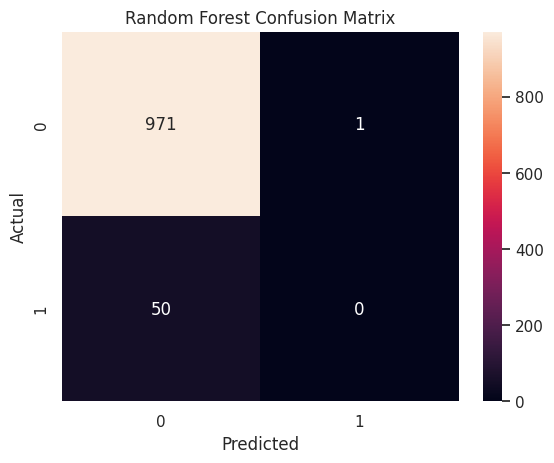

In [31]:
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt="d")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

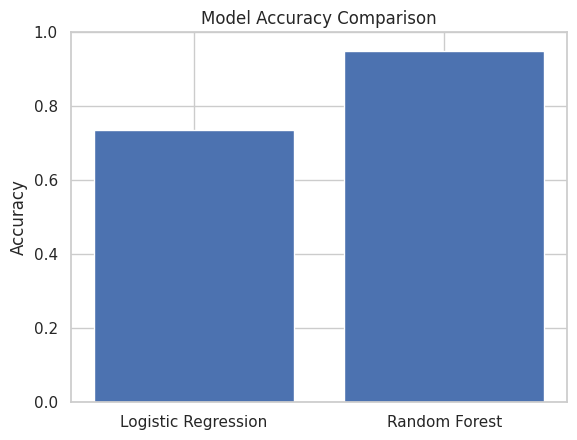

In [32]:
models = ["Logistic Regression", "Random Forest"]

accuracies = [
    accuracy_score(y_test, lr_pred),
    accuracy_score(y_test, rf_pred)
]

plt.bar(models, accuracies)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

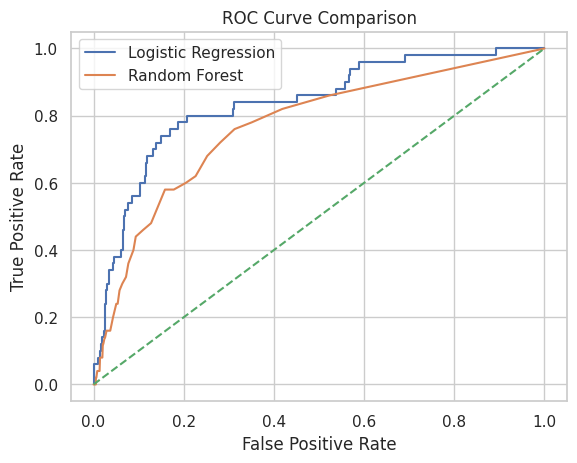

In [33]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)

plt.plot(fpr_lr, tpr_lr, label="Logistic Regression")
plt.plot(fpr_rf, tpr_rf, label="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [34]:
importance = pd.Series(rf.feature_importances_, index=X.columns)

importance = importance.sort_values(ascending=False)

print(importance)

age                  0.393083
avg_glucose_level    0.197005
bmi                  0.181066
work_type            0.051917
smoking_status       0.048078
hypertension         0.034833
ever_married         0.033152
Residence_type       0.022330
gender               0.020782
heart_disease        0.017754
dtype: float64


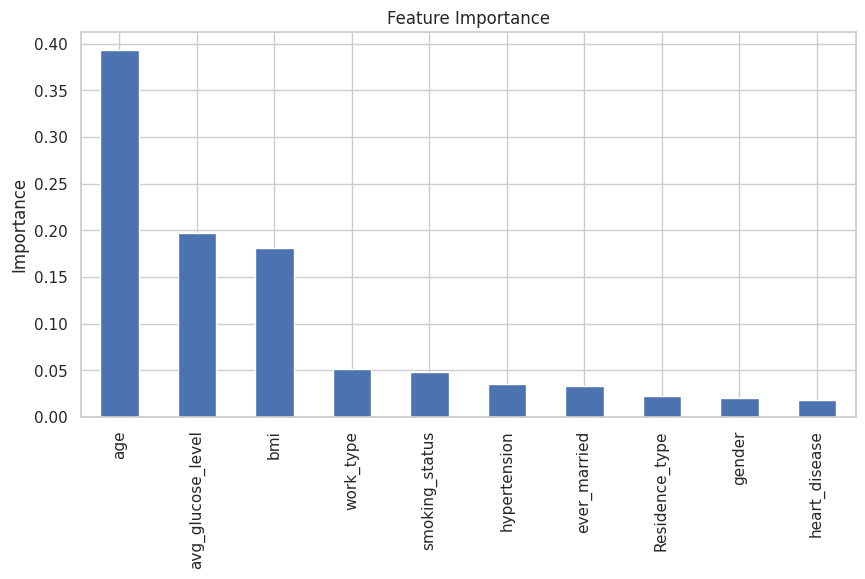

In [35]:
importance.plot(kind="bar", figsize=(10, 5))
plt.title("Feature Importance")
plt.ylabel("Importance")
plt.show()